# Tehdit İstihbaratında İki Parçalı Ağ Analizi (MITRE ATT&CK v20.0)

**Sosyal Ağ Analizi dönem ödevi** · Kaan Semih Kurt (2516016008) · Manisa Celal Bayar Üniversitesi

**Araştırma soruları**
1. Savunma ekibi sınırlı bütçeyle hangi teknikleri öncelikle tespit etmeli?
2. Hangi tehdit grupları benzer davranıyor?

**Ağ:** düğümler tehdit grupları (174) ve teknikler/alt-teknikler (515); kenar = "grup bu tekniği kullanır".
Ağ `src/fetch_build.py` ile ham STIX verisinden kurulur. Bu defter `data/processed/` içindeki dosyaları okur.

**Çalıştırma:** repo kökünde `python src/fetch_build.py`, ardından bu defteri baştan sona çalıştırın.
Tüm rastgele adımlar `SEED = 42` ile sabittir.

In [1]:
import json, random, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from sklearn.metrics import normalized_mutual_info_score as NMI, adjusted_rand_score as ARI, silhouette_score
import powerlaw

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, FIG, RES = ROOT / "data" / "processed", ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
R = {}  # rapor ve sunum için tüm sayısal sonuçlar
print("networkx", nx.__version__, "| powerlaw hazır | SEED =", SEED)

networkx 3.7 | powerlaw hazır | SEED = 42


## 1. Veriyi yükle

In [2]:
nodes = pd.read_csv(PROC / "nodes.csv", keep_default_na=False)
edges = pd.read_csv(PROC / "edges.csv", keep_default_na=False)
B = nx.read_graphml(PROC / "attack_bipartite.graphml")
PG = nx.read_graphml(PROC / "group_projection.graphml")
PT = nx.read_graphml(PROC / "technique_projection.graphml")
meta = json.loads((PROC / "metadata.json").read_text(encoding="utf-8"))

G_nodes = sorted(n for n, d in B.nodes(data=True) if d["node_type"] == "group")
T_nodes = sorted(n for n, d in B.nodes(data=True) if d["node_type"] == "technique")
name = dict(zip(nodes.node_id, nodes.name))
tactic = dict(zip(nodes.node_id, nodes.tactics))
label = lambda n: f"{n} {name[n]}"
print(f"ATT&CK v{meta['attack_version']} | düğüm={B.number_of_nodes()} kenar={B.number_of_edges()} "
      f"| grup={len(G_nodes)} teknik={len(T_nodes)} (alt-teknik={meta['subtechniques_in_network']})")

ATT&CK v20.0 | düğüm=689 kenar=4815 | grup=174 teknik=515 (alt-teknik=335)


## 2. Temel ağ ölçüleri
İki parçalı ağda iki grup ya da iki teknik doğrudan bağlanmaz; bu yüzden **standart kümelenme katsayısı 0'dır**
(üçgen oluşamaz). Kümelenmeyi (a) iki parçalı ağlar için tanımlı Latapy katsayısıyla ve (b) projeksiyonlarda ölçüyoruz.

In [3]:
n, m = B.number_of_nodes(), B.number_of_edges()
comps = sorted(nx.connected_components(B), key=len, reverse=True)
LCC = B.subgraph(comps[0]).copy()
deg_G = np.array([B.degree(g) for g in G_nodes]); deg_T = np.array([B.degree(t) for t in T_nodes])

basic = {
    "düğüm": n, "kenar": m, "grup": len(G_nodes), "teknik": len(T_nodes),
    "yoğunluk (standart)": nx.density(B),
    "yoğunluk (iki parçalı, m/(nG·nT))": m / (len(G_nodes) * len(T_nodes)),
    "bileşen sayısı": len(comps), "en büyük bileşen (düğüm)": len(comps[0]),
    "ort. en kısa yol (en büyük bileşen)": nx.average_shortest_path_length(LCC),
    "çap (en büyük bileşen)": nx.diameter(LCC),
    "kümelenme (standart, üçgen)": nx.transitivity(B),
    "kümelenme (iki parçalı, Latapy)": nx.bipartite.average_clustering(B),
    "derece benzeşimi (assortativity)": nx.degree_assortativity_coefficient(B),
    "grup başına teknik: ortalama": deg_G.mean(), "grup başına teknik: medyan": float(np.median(deg_G)),
    "teknik başına grup: ortalama": deg_T.mean(), "teknik başına grup: medyan": float(np.median(deg_T)),
}
small = [sorted(c) for c in comps[1:]]
for P, tag in [(PG, "grup projeksiyonu"), (PT, "teknik projeksiyonu")]:
    basic[f"{tag}: düğüm"] = P.number_of_nodes()
    basic[f"{tag}: kenar"] = P.number_of_edges()
    basic[f"{tag}: yoğunluk"] = nx.density(P)
    basic[f"{tag}: kümelenme (transitivity)"] = nx.transitivity(P)
    basic[f"{tag}: ağırlıklı ort. kümelenme"] = nx.average_clustering(P, weight="weight")
    Pl = P.subgraph(max(nx.connected_components(P), key=len))
    basic[f"{tag}: ort. en kısa yol"] = nx.average_shortest_path_length(Pl)
    basic[f"{tag}: çap"] = nx.diameter(Pl)
    basic[f"{tag}: bileşen sayısı"] = nx.number_connected_components(P)

R["basic"] = {k: (float(v) if isinstance(v, (np.floating, float)) else int(v)) for k, v in basic.items()}
R["small_components"] = [[label(x) for x in c] for c in small]
display(pd.Series(basic, name="değer").to_frame().style.format(precision=4))
print("Ana bileşen dışındaki küçük bileşenler:", R["small_components"])

,değer
düğüm,689.0000
kenar,4815.0000
grup,174.0000
teknik,515.0000
yoğunluk (standart),0.0203
"yoğunluk (iki parçalı, m/(nG·nT))",0.0537
bileşen sayısı,1.0000
en büyük bileşen (düğüm),689.0000
ort. en kısa yol (en büyük bileşen),3.1332
çap (en büyük bileşen),7.0000


Ana bileşen dışındaki küçük bileşenler: []


**Yorum (temel ölçüler)**
* **689 düğüm / 4.815 kenar, iki parçalı yoğunluk 0,054:** olası grup–teknik çiftlerinin yalnızca %5,4'ü gözlenmiş. Ortalama grup 27,7 teknik (medyan 19) kullanıyor; yani her grup ATT&CK'in küçük bir alt kümesini kullanıyor.
* **Tek bileşen:** her grup en az bir tekniği başka bir grupla paylaşıyor; tamamen kendine özgü, kopuk bir grup yok.
* **Ortalama en kısa yol 3,13, çap 7:** iki grup tipik olarak "grup → ortak teknik → grup" (2 adım) ile bağlanıyor. Grup projeksiyonunda ortalama yol 1,22 ve yoğunluk 0,78: grup çiftlerinin %78'i en az bir tekniği doğrudan paylaşıyor.
* **Standart kümelenme 0** (iki parçalı ağda üçgen olamaz); **Latapy kümelenmesi 0,108**: bir tekniği kullanan grupların teknik kümeleri ortalama ~%11 örtüşüyor.
* **Derece benzeşimi −0,28 (negatif):** çok tekniği belgelenmiş gruplar nadir tekniklere de bağlanıyor; az belgelenmiş gruplar ise çoğunlukla popüler tekniklerle görünüyor. Nadir teknik bilgisi büyük ölçüde iyi raporlanmış gruplarda toplanıyor.
* **Projeksiyon kümelenmesi (transitivity) 0,89 yüksek görünüyor**, ancak null model bölümünde göreceğimiz gibi bu değer rastgele ağlarla aynı; projeksiyonun doğal sonucu, bulgu değil.

## 3. Derece dağılımı ve kuvvet yasası testi (`powerlaw`)
Grupların derecesi = kullandığı teknik sayısı; tekniklerin derecesi = onu kullanan grup sayısı.
Kuvvet yasasını (Clauset–Shalizi–Newman yöntemi) log-normal ve üstel dağılımla log-olabilirlik oranı (R, p) ile karşılaştırıyoruz.
R > 0 kuvvet yasası lehine, R < 0 alternatif lehine; p < 0,1 ise fark anlamlı kabul edilir.

,alpha,xmin,KS_D,kuyruktaki düğüm,R(PL vs lognormal),p(PL vs lognormal),R(PL vs exponential),p(PL vs exponential)
taraf,,,,,,,,
grup,2.784,28.000,0.162,70,-2.267,0.023,-3.212,0.001
teknik,1.787,3.000,0.093,319,-4.201,0.000,0.388,0.698


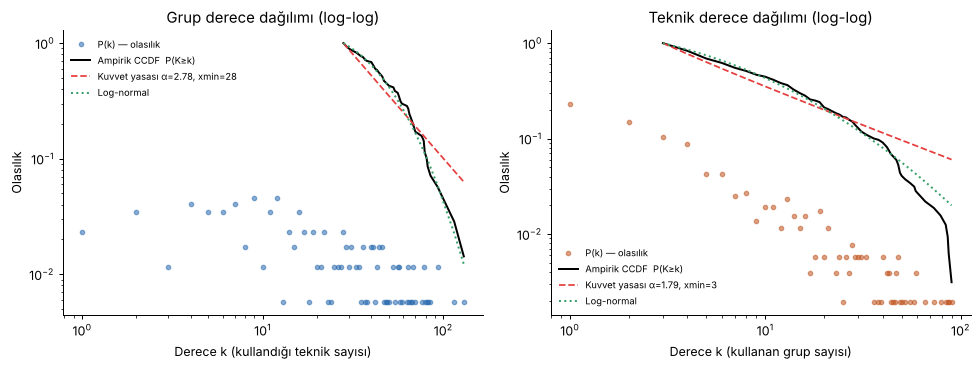

In [4]:
fits, pl_rows = {}, []
for key, d in [("grup", deg_G), ("teknik", deg_T)]:
    try:  # powerlaw >= 2.0: tüm tamsayı xmin adaylarını dene (klasik Clauset yöntemi)
        fit = powerlaw.Fit(d, discrete=True, verbose=False, test_all_xmin=True)
    except TypeError:  # eski sürümler
        fit = powerlaw.Fit(d, discrete=True, verbose=False)
    fits[key] = fit
    row = {"taraf": key, "alpha": fit.power_law.alpha, "xmin": fit.power_law.xmin,
           "KS_D": fit.power_law.D, "kuyruktaki düğüm": int((d >= fit.power_law.xmin).sum())}
    for alt in ["lognormal", "exponential"]:
        Rv, p = fit.distribution_compare("power_law", alt, normalized_ratio=True)
        row[f"R(PL vs {alt})"], row[f"p(PL vs {alt})"] = Rv, p
    pl_rows.append(row)
pl_df = pd.DataFrame(pl_rows).set_index("taraf")
R["powerlaw"] = pl_df.reset_index().to_dict(orient="records")
display(pl_df.style.format(precision=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (key, d, col) in zip(axes, [("grup", deg_G, "#2b6cb0"), ("teknik", deg_T, "#c05621")]):
    vals, cnts = np.unique(d, return_counts=True)
    ax.loglog(vals, cnts / cnts.sum(), "o", ms=3.5, alpha=.55, color=col, label="P(k) — olasılık")
    fit = fits[key]
    fit.plot_ccdf(ax=ax, color="black", lw=1.6, label="Ampirik CCDF  P(K≥k)")
    fit.power_law.plot_ccdf(ax=ax, color="#e53e3e", ls="--", lw=1.4,
                            label=f"Kuvvet yasası α={fit.power_law.alpha:.2f}, xmin={fit.power_law.xmin:.0f}")
    fit.lognormal.plot_ccdf(ax=ax, color="#38a169", ls=":", lw=1.6, label="Log-normal")
    ax.set_xlabel("Derece k (" + ("kullandığı teknik sayısı" if key == "grup" else "kullanan grup sayısı") + ")")
    ax.set_ylabel("Olasılık"); ax.set_title(f"{key.capitalize()} derece dağılımı (log-log)")
    ax.legend(fontsize=7.5, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "fig_degree_distribution.png", bbox_inches="tight"); plt.show()

**Yorum (derece dağılımı)**
* **Teknik tarafı ağır kuyruklu:** tekniklerin medyanı 4 grup, ama T1105 Ingress Tool Transfer 90 grupça (%52) kullanılıyor. Kuvvet yasası uydurulduğunda α ≈ 1,79 (xmin = 3); ancak **log-normal anlamlı biçimde daha iyi** (R = −4,2, p < 0,001), üstel ile fark anlamlı değil. Yani "ölçekten bağımsız ağ" demek yanlış olur: dağılım ağır kuyruklu ama log-normal benzeri.
* **Grup tarafı:** xmin = 28 üstünde α ≈ 2,78; log-normal (p = 0,02) ve üstel (p = 0,001) kuvvet yasasından daha iyi. Grupların belgelenme düzeyi kuvvet yasası izlemiyor.
* **Savunma açısından:** birkaç "evrensel" teknik çok sayıda grubu kapsıyor; bu durum 7c'deki kapsama analizinin neden birkaç teknikle bu kadar yüksek kapsama verdiğini açıklıyor.

## 4. Merkeziyet ölçüleri (iki parçalı ağ üzerinde)
* **Derece:** bir tekniği kaç grup kullanıyor / bir grup kaç teknik kullanıyor.
* **Betweenness:** düğüm, diğer düğümler arasındaki en kısa yolların ne kadarının üzerinde? Teknik için: farklı grup kümelerini birbirine bağlayan "köprü" teknik.
* **Closeness:** ağın geri kalanına ortalama ne kadar yakın?
* **PageRank / Eigenvector:** önemli düğümlere bağlı olmak önemi artırır (çok teknik kullanan gruplarca kullanılan teknik daha önemli sayılır).

In [5]:
cent = pd.DataFrame(index=sorted(B.nodes))
cent["derece"] = pd.Series(dict(B.degree()))
cent["betweenness"] = pd.Series(nx.betweenness_centrality(B))
cent["closeness"] = pd.Series(nx.closeness_centrality(B))
cent["pagerank"] = pd.Series(nx.pagerank(B, alpha=0.85))
cent["eigenvector"] = pd.Series(nx.eigenvector_centrality_numpy(B))
cent["tür"] = [B.nodes[x]["node_type"] for x in cent.index]
cent["ad"] = [name[x] for x in cent.index]
MEAS = ["derece", "betweenness", "closeness", "pagerank", "eigenvector"]
cent.to_csv(RES / "centrality.csv")

top_t = {mm: cent[cent.tür == "technique"].nlargest(10, mm)[["ad", mm]] for mm in MEAS}
top_g = {mm: cent[cent.tür == "group"].nlargest(10, mm)[["ad", mm]] for mm in MEAS}
tbl_t = pd.DataFrame({mm: [f"{i} {r.ad[:28]}" for i, r in top_t[mm].iterrows()] for mm in MEAS}, index=range(1, 11))
tbl_g = pd.DataFrame({mm: [f"{i} {r.ad[:22]}" for i, r in top_g[mm].iterrows()] for mm in MEAS}, index=range(1, 11))
print("İLK 10 TEKNİK"); display(tbl_t)
print("İLK 10 GRUP"); display(tbl_g)

sp_all = cent[MEAS].corr(method="spearman")
sp_t = cent[cent.tür == "technique"][MEAS].corr(method="spearman")
sp_g = cent[cent.tür == "group"][MEAS].corr(method="spearman")
print("Spearman korelasyonu — teknikler"); display(sp_t.round(3))
print("Spearman korelasyonu — gruplar"); display(sp_g.round(3))

R["top_techniques"] = {mm: [[i, r.ad, float(r[mm])] for i, r in top_t[mm].iterrows()] for mm in MEAS}
R["top_groups"] = {mm: [[i, r.ad, float(r[mm])] for i, r in top_g[mm].iterrows()] for mm in MEAS}
R["spearman_techniques"] = sp_t.round(3).to_dict(); R["spearman_groups"] = sp_g.round(3).to_dict()
R["spearman_all"] = sp_all.round(3).to_dict()
# Dereceye göre beklenenden yüksek betweenness: köprü teknikler
tt = cent[cent.tür == "technique"].copy()
tt["deg_rank"] = tt.derece.rank(ascending=False); tt["btw_rank"] = tt.betweenness.rank(ascending=False)
bridges = tt[(tt.btw_rank <= 40)].assign(fark=lambda x: x.deg_rank - x.btw_rank).nlargest(5, "fark")
R["bridge_techniques"] = [[i, r.ad, int(r.derece), float(r.betweenness), int(r.deg_rank), int(r.btw_rank)] for i, r in bridges.iterrows()]
print("Derecesine göre betweenness'ı yüksek 'köprü' teknikler"); display(bridges[["ad", "derece", "betweenness", "deg_rank", "btw_rank"]])

İLK 10 TEKNİK


,derece,betweenness,closeness,pagerank,eigenvector
1,T1105 Ingress Tool Transfer,T1588.002 Tool,T1588.002 Tool,T1105 Ingress Tool Transfer,T1105 Ingress Tool Transfer
2,T1204.002 Malicious File,T1059.001 PowerShell,T1059.001 PowerShell,T1204.002 Malicious File,T1059.001 PowerShell
3,T1059.001 PowerShell,T1105 Ingress Tool Transfer,T1105 Ingress Tool Transfer,T1588.002 Tool,T1588.002 Tool
4,T1588.002 Tool,T1204.002 Malicious File,T1036.005 Match Legitimate Resource Na,T1059.001 PowerShell,T1204.002 Malicious File
5,T1566.001 Spearphishing Attachment,T1566.001 Spearphishing Attachment,T1059.003 Windows Command Shell,T1566.001 Spearphishing Attachment,T1059.003 Windows Command Shell
6,T1059.003 Windows Command Shell,T1059.003 Windows Command Shell,T1204.002 Malicious File,T1059.003 Windows Command Shell,T1566.001 Spearphishing Attachment
7,T1036.005 Match Legitimate Resource Na,T1036.005 Match Legitimate Resource Na,T1082 System Information Discovery,T1036.005 Match Legitimate Resource Na,T1036.005 Match Legitimate Resource Na
8,T1082 System Information Discovery,T1071.001 Web Protocols,T1083 File and Directory Discovery,T1071.001 Web Protocols,T1547.001 Registry Run Keys / Startup
9,T1547.001 Registry Run Keys / Startup,T1082 System Information Discovery,T1547.001 Registry Run Keys / Startup,T1082 System Information Discovery,T1053.005 Scheduled Task
10,T1071.001 Web Protocols,T1078 Valid Accounts,T1071.001 Web Protocols,T1547.001 Registry Run Keys / Startup,T1082 System Information Discovery


İLK 10 GRUP


,derece,betweenness,closeness,pagerank,eigenvector
1,G0094 Kimsuky,G0094 Kimsuky,G0094 Kimsuky,G0094 Kimsuky,G0094 Kimsuky
2,G0082 APT38,G0082 APT38,G0082 APT38,G0082 APT38,G0082 APT38
3,G0007 APT28,G0007 APT28,G0032 Lazarus Group,G0007 APT28,G0032 Lazarus Group
4,G0032 Lazarus Group,G0129 Mustang Panda,G0007 APT28,G0032 Lazarus Group,G0050 APT32
5,G0129 Mustang Panda,G0016 APT29,G0129 Mustang Panda,G0129 Mustang Panda,G0059 Magic Hound
6,G0096 APT41,G0032 Lazarus Group,G0096 APT41,G1017 Volt Typhoon,G0129 Mustang Panda
7,G1017 Volt Typhoon,G1045 Salt Typhoon,G0034 Sandworm Team,G0096 APT41,G0049 OilRig
8,G0034 Sandworm Team,G1017 Volt Typhoon,G0049 OilRig,G0016 APT29,G0096 APT41
9,G0050 APT32,G1015 Scattered Spider,G0050 APT32,G1045 Salt Typhoon,G0034 Sandworm Team
10,G0059 Magic Hound,G0096 APT41,G0059 Magic Hound,G0034 Sandworm Team,G0069 MuddyWater


Spearman korelasyonu — teknikler


,derece,betweenness,closeness,pagerank,eigenvector
derece,1.000,0.976,0.945,0.988,0.966
betweenness,0.976,1.000,0.943,0.980,0.939
closeness,0.945,0.943,1.000,0.923,0.985
pagerank,0.988,0.980,0.923,1.000,0.934
eigenvector,0.966,0.939,0.985,0.934,1.000


Spearman korelasyonu — gruplar


,derece,betweenness,closeness,pagerank,eigenvector
derece,1.000,0.934,0.973,0.992,0.966
betweenness,0.934,1.000,0.884,0.965,0.856
closeness,0.973,0.884,1.000,0.953,0.980
pagerank,0.992,0.965,0.953,1.000,0.937
eigenvector,0.966,0.856,0.980,0.937,1.000


Derecesine göre betweenness'ı yüksek 'köprü' teknikler


,ad,derece,betweenness,deg_rank,btw_rank
T1120,Peripheral Device Discovery,9,0.006743,146.0,31.0
T1585.001,Social Media Accounts,23,0.005543,58.5,40.0
T1583.006,Web Services,29,0.008209,43.0,25.0
T1133,External Remote Services,28,0.006603,46.5,33.0
T1587.001,Malware,27,0.006028,49.5,37.0


**Yorum (merkeziyet)**
* **Teknik tarafında ilk 10 neredeyse tüm ölçülerde aynı** (T1105, T1204.002, T1059.001, T1588.002, T1566.001, T1059.003 …) ve Spearman korelasyonları 0,86–0,99. Bu ağda "merkezi teknik" büyük ölçüde "yaygın teknik" demek; ölçüler birbirinin yerine geçebilecek kadar ilişkili.
* **Betweenness'ta T1588.002 Tool birinci:** hazır araç edinme (Mimikatz, Cobalt Strike gibi), farklı topluluklardaki grupları birbirine bağlayan ortak araç zinciri. Bu tekniğin tespiti, birbirine en uzak grup aileleri arasında ortak bir "kontrol noktası" sağlar.
* **Köprü teknikler:** örneğin T1120 Peripheral Device Discovery yalnızca 9 grupça kullanılıyor (derece sırası 146), ama betweenness sırası 31. Az sayıda, fakat birbirine benzemeyen grubu bağlıyor.
* **Grup tarafında en merkezde Kimsuky, APT38, APT28, Lazarus Group:** bunlar en çok raporlanan gruplar. Grup merkeziyeti "en tehlikeli grup"tan çok **raporlanma yoğunluğunu** yansıtıyor (bkz. sınırlar).

## 5. Topluluk tespiti: Louvain ve Leiden (grup–grup projeksiyonu, Newman ağırlıklı)
Projeksiyonda iki grup arasındaki ağırlık, paylaştıkları tekniklerden gelir; yaygın teknik (çok grup kullanıyor) az, nadir teknik çok katkı verir.
Her algoritma 10 farklı tohumla çalıştırılır; tohumlar arası benzerlik NMI ve ARI ile ölçülür (1 = aynı bölümleme).

In [6]:
def to_labels(parts, order):
    lab = {}
    for i, c in enumerate(sorted(parts, key=lambda c: (-len(c), min(c)))):
        for x in c:
            lab[x] = i
    return [lab[x] for x in order]

def _on_int_labels(algo):
    """Düğümleri sıralı tamsayılara çevirip algoritmayı çalıştırır, sonra adları geri koyar.
    Neden: metin etiketlerinin küme (set) sırası Python oturumuna göre değişebilir; tamsayı etiketlerle
    aynı tohum her makinede aynı sonucu verir (tekrarlanabilirlik)."""
    def run(G, s):
        H = nx.convert_node_labels_to_integers(G, ordering="sorted", label_attribute="orig")
        back = nx.get_node_attributes(H, "orig")
        return [{back[x] for x in c} for c in algo(H, s)]
    return run

ALGOS = {
    "Louvain": _on_int_labels(lambda G, s: nx.community.louvain_communities(G, weight="weight", seed=s)),
    "Leiden": _on_int_labels(lambda G, s: nx.community.leiden_communities(G, weight="weight", seed=s, metric="modularity")),
}
SEEDS = list(range(SEED, SEED + 10))

def community_study(P, tag):
    order = sorted(P.nodes)
    out, best = {}, {}
    for algo, f in ALGOS.items():
        runs = [f(P, s) for s in SEEDS]
        mods = [nx.community.modularity(P, r, weight="weight") for r in runs]
        labs = [to_labels(r, order) for r in runs]
        nmi = [NMI(labs[i], labs[j]) for i in range(10) for j in range(i + 1, 10)]
        ari = [ARI(labs[i], labs[j]) for i in range(10) for j in range(i + 1, 10)]
        b = int(np.argmax(mods)); best[algo] = runs[b]
        out[algo] = {"modularity_mean": float(np.mean(mods)), "modularity_sd": float(np.std(mods)),
                     "modularity_best": float(mods[b]), "n_comm_best": len(runs[b]),
                     "sizes_best": sorted([len(c) for c in runs[b]], reverse=True),
                     "n_comm_range": [min(len(r) for r in runs), max(len(r) for r in runs)],
                     "NMI_mean": float(np.mean(nmi)), "NMI_min": float(np.min(nmi)),
                     "ARI_mean": float(np.mean(ari)), "ARI_min": float(np.min(ari))}
    la, le = to_labels(best["Louvain"], order), to_labels(best["Leiden"], order)
    out["Louvain_vs_Leiden"] = {"NMI": float(NMI(la, le)), "ARI": float(ARI(la, le))}
    print(f"== {tag} =="); display(pd.DataFrame({k: v for k, v in out.items() if k != "Louvain_vs_Leiden"}).T)
    print("En iyi Louvain vs en iyi Leiden:", out["Louvain_vs_Leiden"])
    return out, best

R["communities_group"], best_G = community_study(PG, "Grup projeksiyonu")
R["communities_technique"], best_T = community_study(PT, "Teknik projeksiyonu")

== Grup projeksiyonu ==


,modularity_mean,modularity_sd,modularity_best,n_comm_best,sizes_best,n_comm_range,NMI_mean,NMI_min,ARI_mean,ARI_min
Louvain,0.09174,0.0009,0.092387,4,"[75, 56, 28, 15]","[3, 4]",0.712726,0.525334,0.762067,0.572392
Leiden,0.091229,0.001213,0.092387,4,"[75, 56, 28, 15]","[3, 4]",0.687052,0.523991,0.736411,0.569286


En iyi Louvain vs en iyi Leiden: {'NMI': 1.0, 'ARI': 1.0}
== Teknik projeksiyonu ==


,modularity_mean,modularity_sd,modularity_best,n_comm_best,sizes_best,n_comm_range,NMI_mean,NMI_min,ARI_mean,ARI_min
Louvain,0.108634,0.00082,0.109814,5,"[166, 135, 125, 83, 6]","[4, 5]",0.726103,0.563588,0.740101,0.487187
Leiden,0.108643,0.000907,0.109803,5,"[182, 131, 114, 77, 11]","[4, 5]",0.725032,0.615423,0.757054,0.628192


En iyi Louvain vs en iyi Leiden: {'NMI': 0.8537120696494542, 'ARI': 0.8709309391141847}


### Toplulukların içeriği ve adlandırma
Final bölümleme: en yüksek modülerlikli **Leiden** sonucu. Her topluluk için (a) en çok tekniği belgelenmiş üyeler,
(b) ayırt edici teknikler (topluluk içi kullanım oranı / genel kullanım oranı = *lift*) ve
(c) MITRE açıklamalarında geçen atıf/motivasyon anahtar kelimeleri incelendi.

In [7]:
comm_list = sorted(best_G["Leiden"], key=lambda c: (-len(c), min(c)))
gcomm = {g: i for i, c in enumerate(comm_list) for g in c}
desc = dict(zip(nodes.node_id, nodes.description))
full_desc = {}
_raw = json.loads((ROOT / "data" / "raw" / f"enterprise-attack-v{meta['attack_version']}.json").read_text(encoding="utf-8"))["objects"] \
    if (ROOT / "data" / "raw" / f"enterprise-attack-v{meta['attack_version']}.json").exists() else []
stix2id = dict(zip(nodes.stix_id, nodes.node_id))
for o in _raw:
    if o.get("type") == "intrusion-set" and o["id"] in stix2id:
        full_desc[stix2id[o["id"]]] = (o.get("description", "") + " " + " ".join(o.get("aliases", []))).lower()
del _raw
KEYS = {"Çin": ["china", "chinese", "prc"], "Rusya": ["russia", "russian", "gru", "svr", "fsb"],
        "İran": ["iran", "iranian", "irgc"], "K. Kore": ["north korea", "dprk"],
        "Finansal": ["financial", "financially motivated", "ransomware", "cybercrim"],
        "Vietnam": ["vietnam"], "Pakistan/Hindistan": ["pakistan", "india"], "Orta Doğu": ["middle east", "israel", "lebanon", "palestin"]}
overall_share = {t: B.degree(t) / len(G_nodes) for t in T_nodes}
comm_info = []
for i, c in enumerate(comm_list):
    members = sorted(c, key=lambda g: (-B.degree(g), g))
    cnt = {}
    for g in c:
        for t in B[g]:
            cnt[t] = cnt.get(t, 0) + 1
    lift = sorted(((cnt[t] / len(c)) / overall_share[t], t) for t in cnt if cnt[t] / len(c) >= 0.25)[::-1][:8]
    common = sorted(cnt, key=lambda t: -cnt[t])[:5]
    kw = {k: sum(any(w in full_desc.get(g, "") for w in ws) for g in c) for k, ws in KEYS.items()}
    comm_info.append({"id": i, "size": len(c), "top_members": [label(g) for g in members[:10]],
                      "distinctive": [[label(t), round(l, 2), round(cnt[t] / len(c), 2)] for l, t in lift],
                      "most_common": [[label(t), round(cnt[t] / len(c), 2)] for t in common],
                      "keywords": kw, "median_techniques": float(np.median([B.degree(g) for g in c]))})
for ci in comm_info:
    print(f"\n### Topluluk {ci['id']} — {ci['size']} grup, medyan teknik sayısı {ci['median_techniques']}")
    print("Öne çıkan üyeler:", ", ".join(ci["top_members"][:8]))
    print("Ayırt edici teknikler (lift, topluluk içi oran):", ci["distinctive"][:6])
    print("En yaygın teknikler:", ci["most_common"])
    print("Açıklama anahtar kelimeleri:", ci["keywords"])


### Topluluk 0 — 75 grup, medyan teknik sayısı 14.0
Öne çıkan üyeler: G0050 APT32, G0047 Gamaredon Group, G0069 MuddyWater, G0046 FIN7, G0065 Leviathan, G1006 Earth Lusca, G0040 Patchwork, G1039 RedCurl
Ayırt edici teknikler (lift, topluluk içi oran): [['T1189 Drive-by Compromise', 1.65, 0.29], ['T1059.005 Visual Basic', 1.61, 0.43], ['T1566.001 Spearphishing Attachment', 1.59, 0.72], ['T1204.002 Malicious File', 1.55, 0.77], ['T1204.001 Malicious Link', 1.48, 0.43], ['T1027.013 Encrypted/Encoded File', 1.39, 0.32]]
En yaygın teknikler: [['T1204.002 Malicious File', 0.77], ['T1566.001 Spearphishing Attachment', 0.72], ['T1105 Ingress Tool Transfer', 0.56], ['T1059.005 Visual Basic', 0.43], ['T1204.001 Malicious Link', 0.43]]
Açıklama anahtar kelimeleri: {'Çin': 24, 'Rusya': 13, 'İran': 7, 'K. Kore': 3, 'Finansal': 16, 'Vietnam': 4, 'Pakistan/Hindistan': 10, 'Orta Doğu': 11}

### Topluluk 1 — 56 grup, medyan teknik sayısı 25.0
Öne çıkan üyeler: G0096 APT41, G1017 Volt Typhoon, G0059 Ma

In [8]:
# Toplulukların adları — yukarıdaki içerik incelemesine göre verildi (TR / EN)
COMM_NAMES = {
    0: ("Oltalama ve zararlı belgeyle sızanlar", "Phishing & malicious-document operators"),
    1: ("Ağ içi keşif ve yanal hareket ustaları", "Network discovery & lateral-movement crews"),
    2: ("Bulut, Linux ve güvenilen ilişki saldırganları", "Cloud, Linux & trusted-relationship intruders"),
    3: ("Sosyal mühendislik ve kimlik bilgisi avcıları", "Social-engineering & credential harvesters"),
}
for ci in comm_info:
    ci["name_tr"], ci["name_en"] = COMM_NAMES.get(ci["id"], (f"Topluluk {ci['id']}", f"Community {ci['id']}"))
R["community_info"] = comm_info
display(pd.DataFrame([{"topluluk": ci["id"], "ad": ci["name_tr"], "grup sayısı": ci["size"],
                       "örnek üyeler": ", ".join(x.split(" ", 1)[1] for x in ci["top_members"][:5])} for ci in comm_info]))

,topluluk,ad,grup sayısı,örnek üyeler
0,0,Oltalama ve zararlı belgeyle sızanlar,75,"APT32, Gamaredon Group, MuddyWater, FIN7, Levi..."
1,1,Ağ içi keşif ve yanal hareket ustaları,56,"APT41, Volt Typhoon, Magic Hound, OilRig, Turla"
2,2,"Bulut, Linux ve güvenilen ilişki saldırganları",28,"APT38, APT28, APT29, NIMBUS MANTICORE, Scatter..."
3,3,Sosyal mühendislik ve kimlik bilgisi avcıları,15,"Kimsuky, Lazarus Group, Mustang Panda, Sandwor..."


**Yorum (topluluklar)**
* **Grup projeksiyonu:** Louvain ve Leiden'in en iyi çözümleri **birebir aynı** (NMI = ARI = 1,0): 4 topluluk, modülerlik 0,092.
* **Modülerlik neden düşük?** Projeksiyon çok yoğun (%78) ve gruplar ortak bir teknik havuzundan besleniyor; keskin sınırlar yok. Yine de bu değer rastgele ağlardakinin iki katı (z ≈ 30, bölüm 6).
* **Kararlılık:** 10 tohum arasında NMI ≈ 0,69–0,71, ARI ≈ 0,74–0,76; topluluk sayısı 3–4. Çekirdek yapı kararlı, sınırdaki bazı gruplar topluluk değiştiriyor.
* **Topluluklar ülkeye değil saldırı tarzına göre ayrışıyor:** örneğin "oltalama" topluluğunda Çin, Rusya, İran bağlantılı ve finansal motivasyonlu gruplar birlikte. Ayırt edici teknikler (lift) toplulukların adlarını belirledi: oltalama/zararlı belge, ağ içi keşif ve yanal hareket, bulut/Linux/güvenilen ilişki, sosyal mühendislik ve kimlik bilgisi toplama.

## 6. Null model: aynı derece dizisine sahip 100 rastgele iki parçalı ağ
Rastgele ağlar **iki parçalı derece korumalı kenar takası** ile üretilir: (g1,t1),(g2,t2) → (g1,t2),(g2,t1).
Böylece her grubun kaç teknik kullandığı ve her tekniğin kaç grupça kullanıldığı aynen korunur; sadece *kimin neyi kullandığı* karışır.
Neden Erdős–Rényi değil? Projeksiyon, popüler teknikler yüzünden kendiliğinden yoğun ve üçgenli olur; ER ile kıyaslamak bu etkiyi "bulgu" sanmamıza yol açar.
Her rastgele ağın grup projeksiyonunda kümelenme, ortalama yol ve Louvain modülerliği hesaplanır; z = (gerçek − ortalama) / std.

100 rastgele ağ 268 sn'de üretildi.


,gerçek,null ort.,null std,z-skoru,"p (tek yönlü, ampirik)"
kümelenme (transitivity),0.8934,0.8953,0.0037,-0.5098,0.3366
ağırlıklı ort. kümelenme,0.0243,0.0334,0.0044,-2.0696,0.0297
ort. en kısa yol,1.2183,1.1799,0.0090,4.2796,0.0099
yoğunluk,0.7824,0.8196,0.0091,-4.0820,0.0099
modülerlik (Louvain),0.0923,0.0431,0.0017,29.7109,0.0099


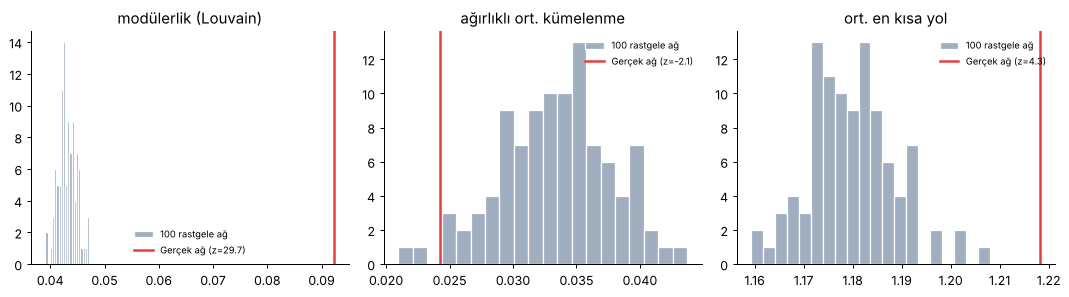

In [9]:
def bipartite_rewire(B, rng, swaps_per_edge=10):
    E = [(a, b) if B.nodes[a]["node_type"] == "group" else (b, a) for a, b in B.edges()]
    S = set(E); m = len(E); done = 0; tries = 0
    while done < swaps_per_edge * m and tries < 100 * m:
        tries += 1
        i, j = rng.integers(m), rng.integers(m)
        (g1, t1), (g2, t2) = E[i], E[j]
        if g1 == g2 or t1 == t2 or (g1, t2) in S or (g2, t1) in S:
            continue
        S.discard((g1, t1)); S.discard((g2, t2)); S.add((g1, t2)); S.add((g2, t1))
        E[i], E[j] = (g1, t2), (g2, t1); done += 1
    H = nx.Graph(); H.add_nodes_from(B.nodes(data=True)); H.add_edges_from(E)
    return H

def proj_metrics(Bx, seed):
    P = nx.bipartite.collaboration_weighted_projected_graph(Bx, G_nodes)
    for u, v, d in P.edges(data=True):
        d["weight"] = round(d["weight"], 6)  # gerçek projeksiyonla aynı hassasiyet; toplama sırası farkını siler
    Pl = P.subgraph(max(nx.connected_components(P), key=len))
    comm = ALGOS["Louvain"](P, seed)
    return {"kümelenme (transitivity)": nx.transitivity(P),
            "ağırlıklı ort. kümelenme": nx.average_clustering(P, weight="weight"),
            "ort. en kısa yol": nx.average_shortest_path_length(Pl),
            "yoğunluk": nx.density(P),
            "modülerlik (Louvain)": nx.community.modularity(P, comm, weight="weight")}

N_NULL = 100
rng = np.random.default_rng(SEED)
obs = proj_metrics(B, SEED)
t0 = time.time()
import os
if os.environ.get("SNA_USE_NULL_CACHE") == "1" and (RES / "null_model_runs.csv").exists():
    null = pd.read_csv(RES / "null_model_runs.csv")  # yalnız geliştirme sırasında hızlı tekrar için
else:
    null = pd.DataFrame([proj_metrics(bipartite_rewire(B, rng), SEED + k) for k in range(N_NULL)])
print(f"{N_NULL} rastgele ağ {time.time() - t0:.0f} sn'de üretildi.")
null.to_csv(RES / "null_model_runs.csv", index=False)
z = pd.DataFrame({"gerçek": pd.Series(obs), "null ort.": null.mean(), "null std": null.std(ddof=1)})
z["z-skoru"] = (z["gerçek"] - z["null ort."]) / z["null std"]
z["p (tek yönlü, ampirik)"] = [((null[c] >= obs[c]).sum() + 1) / (N_NULL + 1) if obs[c] >= null[c].mean()
                               else ((null[c] <= obs[c]).sum() + 1) / (N_NULL + 1) for c in z.index]
R["null_model"] = z.reset_index().rename(columns={"index": "ölçü"}).to_dict(orient="records")
display(z.style.format(precision=4))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, c in zip(axes, ["modülerlik (Louvain)", "ağırlıklı ort. kümelenme", "ort. en kısa yol"]):
    ax.hist(null[c], bins=20, color="#a0aec0", edgecolor="white", label="100 rastgele ağ")
    ax.axvline(obs[c], color="#e53e3e", lw=2, label=f"Gerçek ağ (z={z.loc[c, 'z-skoru']:.1f})")
    ax.set_title(c); ax.legend(fontsize=7.5, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "fig_null_model.png", bbox_inches="tight"); plt.show()

**Yorum (null model)**
* **Modülerlik:** gerçek ağda 0,092; aynı derece dizisine sahip 100 rastgele ağda 0,043 ± 0,002 (**z ≈ 30**). Topluluk yapısı rastlantı değil: gruplar teknikleri belirli "aileler" hâlinde paylaşıyor.
* **Kümelenme (transitivity):** gerçek 0,893, null 0,895 (z ≈ −0,5). Projeksiyondaki yüksek kümelenme **tamamen derece dizisinden** geliyor. Null model olmasaydı "gruplar arasında yüksek kümelenme var" diye yanlış bir iddiada bulunurduk.
* **Rastgeleden "seçici":** gerçek ağda ağırlıklı kümelenme daha düşük (z ≈ −2,1), ortalama yol daha uzun (z ≈ +4,3), yoğunluk daha düşük (z ≈ −4,1). Gruplar teknikleri rastgele dağıtımdan daha seçici paylaşıyor; bazı grup çiftleri hiç ortak teknik kullanmıyor.

## 7. Kişisel ileri yöntem
### 7a. Newman ağırlıklı projeksiyon: neden ham "ortak teknik sayısı" yetmez?
Newman (2001): $w_{ij} = \sum_k \frac{1}{d_k - 1}$ — $k$ i ve j'nin ortak kullandığı teknik, $d_k$ o tekniği kullanan grup sayısı.
100 grubun kullandığı bir teknik iki gruba sadece 1/99 katkı verir; yalnız 2 grubun kullandığı bir teknik tam 1 katkı verir.

In [10]:
pairs = pd.DataFrame([{"g1": u, "g2": v, "newman": d["weight"], "ortak": d["shared"]} for u, v, d in PG.edges(data=True)])
pairs["ad1"] = pairs.g1.map(name); pairs["ad2"] = pairs.g2.map(name)
rank_corr = stats.spearmanr(pairs.newman, pairs.ortak).correlation
top_newman = pairs.nlargest(10, "newman"); top_shared = pairs.nlargest(10, "ortak")
print(f"Newman ağırlığı ile ham ortak teknik sayısı arasındaki Spearman: {rank_corr:.3f}")
print("En güçlü 10 bağ — Newman"); display(top_newman[["ad1", "ad2", "newman", "ortak"]])
print("En güçlü 10 bağ — ham ortak teknik sayısı"); display(top_shared[["ad1", "ad2", "ortak", "newman"]])
R["newman"] = {"spearman_newman_vs_shared": float(rank_corr),
               "top_newman": top_newman[["ad1", "ad2", "newman", "ortak"]].values.tolist(),
               "top_shared": top_shared[["ad1", "ad2", "ortak", "newman"]].values.tolist(),
               "overlap_top10": len(set(map(tuple, top_newman[["g1", "g2"]].values)) & set(map(tuple, top_shared[["g1", "g2"]].values)))}

# Küçük örnek (sunum için): 3 grup, 3 teknik
toy = nx.Graph([("A", "t1"), ("B", "t1"), ("C", "t1"), ("A", "t2"), ("B", "t2"), ("B", "t3"), ("C", "t3")])
toyP = nx.bipartite.collaboration_weighted_projected_graph(toy, ["A", "B", "C"])
print("Oyuncak örnek Newman ağırlıkları:", {f"{u}-{v}": round(d['weight'], 2) for u, v, d in toyP.edges(data=True)})
R["toy"] = {f"{u}-{v}": round(d["weight"], 3) for u, v, d in toyP.edges(data=True)}

Newman ağırlığı ile ham ortak teknik sayısı arasındaki Spearman: 0.918
En güçlü 10 bağ — Newman


,ad1,ad2,newman,ortak
10722,LAPSUS$,Scattered Spider,5.650326,21
8146,Kimsuky,Mustang Panda,5.098433,48
7297,APT38,Kimsuky,4.667036,60
11069,Scattered Spider,Storm-0501,4.557365,17
7290,APT38,Contagious Interview,3.808846,31
7310,APT38,TeamPCP,3.599993,21
4327,Gamaredon Group,Kimsuky,3.102558,45
762,APT28,Kimsuky,2.946596,40
2911,Lazarus Group,Mustang Panda,2.851779,41
7275,APT38,NIMBUS MANTICORE,2.843122,29


En güçlü 10 bağ — ham ortak teknik sayısı


,ad1,ad2,ortak,newman
7297,APT38,Kimsuky,60,4.667036
2888,Lazarus Group,Kimsuky,49,2.841167
8146,Kimsuky,Mustang Panda,48,5.098433
2870,Lazarus Group,APT38,45,2.567706
4327,Gamaredon Group,Kimsuky,45,3.102558
4675,APT32,Kimsuky,45,1.964975
5296,Magic Hound,Kimsuky,45,1.792889
4659,APT32,APT38,44,2.170011
6284,MuddyWater,Kimsuky,44,2.399646
3132,Sandworm Team,Kimsuky,43,2.524467


Oyuncak örnek Newman ağırlıkları: {'A-B': 1.5, 'A-C': 0.5, 'B-C': 1.5}


**Yorum (Newman projeksiyonu)**
* **Genel sıralama benzer, en güçlü bağlar farklı:** ham ortak teknik sayısı ile Newman ağırlığının sıralaması benzer (Spearman 0,92), ama en güçlü 10 bağın yalnızca 3'ü iki listede ortak.
* **Ham sayının yanlılığı:** ham sayı, en çok tekniği belgelenmiş grupları öne çıkarıyor (Kimsuky–APT38: 60 ortak teknik).
* **Newman'ın öne çıkardığı:** nadir teknik paylaşanlar. En güçlü Newman bağı **LAPSUS$–Scattered Spider** (21 ortak teknik); ikisi de sosyal mühendislik ve kimlik bilgisiyle ilerleyen gasp grupları. Bu bağ ham sayıyla ilk 10'a girmiyor.
* **Oyuncak örnek:** t1'i A, B, C kullanıyor (her çifte 1/(3−1) = 0,5 katkı); t2'yi yalnız A ve B kullanıyor (1/(2−1) = 1); t3'ü yalnız B ve C kullanıyor (1). Sonuç: A–B = 1,5, B–C = 1,5, A–C = 0,5.

### 7b. Jaccard benzerliğiyle grup kümeleri
$J(A,B) = |T_A \cap T_B| / |T_A \cup T_B|$ — iki grubun teknik kümelerinin örtüşme oranı (0–1).
Çok az tekniği belgelenmiş gruplarda oran oynak olduğundan kümelemeye **en az 5 tekniği olan** gruplar alındı.
Önce klasik hiyerarşik kümeleme (ortalama bağlantı) denendi: tek dev küme + birkaç tekil grup üretti (zincirleme etkisi, siluet ≈ 0,05).
Bu yüzden **k-en yakın komşu Jaccard ağı** kuruldu: her grup en benzer 5 grubuna Jaccard ağırlığıyla bağlandı, sonra Leiden ile kümelendi (10 tohum).

Hiyerarşik (ortalama bağlantı): en iyi k=3, siluet=0.052, küme boyutları=[152, 2, 1]  -> kullanışsız
k-NN Jaccard ağı: 155 düğüm, 602 kenar | Leiden: 5 küme, modülerlik=0.529, siluet=0.023, tohumlar arası NMI ort.=0.795
Jaccard kümeleri ile Newman-projeksiyonu Leiden toplulukları uyumu: {'NMI': 0.287, 'ARI': 0.218}

Jaccard kümesi 0 (49 grup): APT28, APT41, Volt Typhoon, APT29, Wizard Spider, Chimera, Salt Typhoon, Threat Group-3390, Medusa Group, Dragonfly, TeamTNT, APT39
   ayırt edici: [['T1021.001 Remote Desktop Protocol', 2.64, 0.59], ['T1018 Remote System Discovery', 2.56, 0.63], ['T1021.002 SMB/Windows Admin Shares', 2.54, 0.41], ['T1074.001 Local Data Staging', 2.45, 0.41]]

Jaccard kümesi 1 (34 grup): APT-C-36, TA505, Moonstone Sleet, LuminousMoth, TA2541, WIRTE, LazyScripter, Star Blizzard, Windshift, Confucius, CURIUM, Saint Bear
   ayırt edici: [['T1608.001 Upload Malware', 2.22, 0.38], ['T1204.001 Malicious Link', 2.05, 0.59], ['T1566.002 Spearphishing Link', 2.03, 0.56], 

,ad1,ad2,jaccard,ortak
5857,Elderwood,Mofang,0.500000,5
10282,IndigoZebra,Ferocious Kitten,0.444444,4
5880,Elderwood,Transparent Tribe,0.437500,7
496,APT12,TA459,0.428571,3
6490,Rancor,Machete,0.428571,6
6824,DarkHydrus,Nomadic Octopus,0.400000,4
3607,Patchwork,Sidewinder,0.392157,20
8047,Machete,Transparent Tribe,0.388889,7
5509,TA459,Gallmaker,0.375000,3
8330,APT-C-36,TA2541,0.375000,18


En benzer 10 grup çifti (en az 15 ortak teknik)


,ad1,ad2,jaccard,ortak
3607,Patchwork,Sidewinder,0.392157,20
8330,APT-C-36,TA2541,0.375000,18
2354,Threat Group-3390,menuPass,0.373333,28
6218,MuddyWater,Earth Lusca,0.349398,29
7012,Tropic Trooper,Sidewinder,0.346154,18
8110,APT41,Wizard Spider,0.339450,37
4437,APT32,Magic Hound,0.333333,39
5410,FIN8,Wizard Spider,0.333333,25
7565,WIRTE,TA505,0.333333,15
8720,Rocke,TeamTNT,0.333333,23


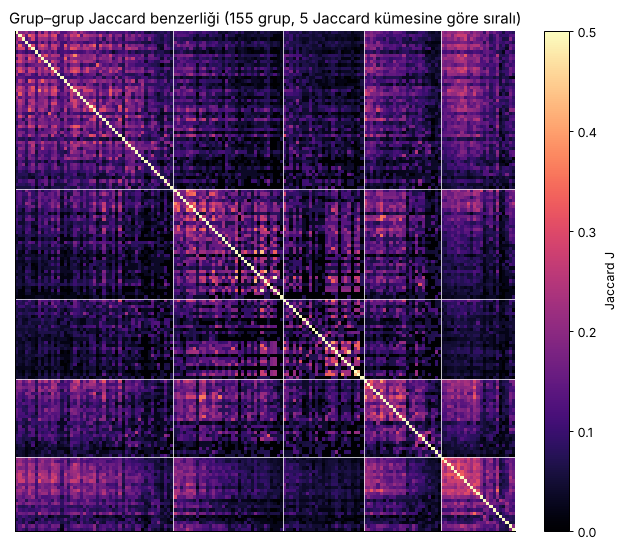

In [11]:
MIN_TECH, K_NN = 5, 5
GJ = [g for g in G_nodes if B.degree(g) >= MIN_TECH]
tset = {g: set(B[g]) for g in G_nodes}
Jm = np.array([[len(tset[a] & tset[b]) / len(tset[a] | tset[b]) for b in GJ] for a in GJ])
D = 1 - Jm; np.fill_diagonal(D, 0)
iu = np.triu_indices(len(GJ), 1)

# (i) hiyerarşik kümeleme denemesi (karşılaştırma için)
Z = hierarchy.linkage(squareform(D, checks=False), method="average")
sil_h = {k: silhouette_score(D, hierarchy.fcluster(Z, k, "maxclust"), metric="precomputed") for k in range(3, 11)}
kh = max(sil_h, key=sil_h.get)
h_sizes = pd.Series(hierarchy.fcluster(Z, kh, "maxclust")).value_counts().tolist()
print(f"Hiyerarşik (ortalama bağlantı): en iyi k={kh}, siluet={sil_h[kh]:.3f}, küme boyutları={h_sizes}  -> kullanışsız")

# (ii) k-NN Jaccard ağı + Leiden
JG = nx.Graph(); JG.add_nodes_from(GJ)
for i, g in enumerate(GJ):
    sims = Jm[i].copy(); sims[i] = -1
    for j in np.argsort(-sims)[:K_NN]:
        JG.add_edge(g, GJ[j], weight=float(Jm[i, j]))
j_runs = [ALGOS["Leiden"](JG, s) for s in SEEDS]
j_mods = [nx.community.modularity(JG, r, weight="weight") for r in j_runs]
j_labs = [to_labels(r, GJ) for r in j_runs]
j_nmi = [NMI(j_labs[i], j_labs[j]) for i in range(10) for j in range(i + 1, 10)]
jbest = sorted(j_runs[int(np.argmax(j_mods))], key=lambda c: (-len(c), min(c)))
jclusters = pd.Series({g: i for i, c in enumerate(jbest) for g in c})
sil_j = silhouette_score(D, jclusters[GJ].values, metric="precomputed")
lei = pd.Series({g: gcomm[g] for g in GJ})
agree = {"NMI": float(NMI(lei[GJ], jclusters[GJ])), "ARI": float(ARI(lei[GJ], jclusters[GJ]))}
print(f"k-NN Jaccard ağı: {JG.number_of_nodes()} düğüm, {JG.number_of_edges()} kenar | Leiden: {len(jbest)} küme, "
      f"modülerlik={max(j_mods):.3f}, siluet={sil_j:.3f}, tohumlar arası NMI ort.={np.mean(j_nmi):.3f}")
print("Jaccard kümeleri ile Newman-projeksiyonu Leiden toplulukları uyumu:", {k: round(v, 3) for k, v in agree.items()})

def describe(c):
    cnt = {}
    for g in c:
        for t in B[g]:
            cnt[t] = cnt.get(t, 0) + 1
    lift = sorted(((cnt[t] / len(c)) / overall_share[t], t) for t in cnt if cnt[t] / len(c) >= 0.3)[::-1][:5]
    return [[label(t), round(l, 2), round(cnt[t] / len(c), 2)] for l, t in lift]

jc_info = []
for i, c in enumerate(jbest):
    mem = sorted(c, key=lambda g: (-B.degree(g), g))
    jc_info.append({"id": i, "size": len(c), "members": [label(g) for g in mem],
                    "distinctive": describe(c),
                    "keywords": {k: sum(any(w in full_desc.get(g, "") for w in ws) for g in c) for k, ws in KEYS.items()}})
for ci in jc_info:
    print(f"\nJaccard kümesi {ci['id']} ({ci['size']} grup):", ", ".join(x.split(" ", 1)[1] for x in ci["members"][:12]))
    print("   ayırt edici:", ci["distinctive"][:4])

pairs_j = pd.DataFrame({"g1": np.array(GJ)[iu[0]], "g2": np.array(GJ)[iu[1]], "jaccard": Jm[iu]})
pairs_j["ortak"] = [len(tset[a] & tset[b]) for a, b in zip(pairs_j.g1, pairs_j.g2)]
pairs_j["ad1"] = pairs_j.g1.map(name); pairs_j["ad2"] = pairs_j.g2.map(name)
jp = pairs_j.nlargest(10, "jaccard")
jp10 = pairs_j[pairs_j.ortak >= 15].nlargest(10, "jaccard")
print("\nEn benzer 10 grup çifti (tümü)"); display(jp[["ad1", "ad2", "jaccard", "ortak"]])
print("En benzer 10 grup çifti (en az 15 ortak teknik)"); display(jp10[["ad1", "ad2", "jaccard", "ortak"]])
R["jaccard"] = {"n_groups": len(GJ), "excluded": len(G_nodes) - len(GJ), "k_nn": K_NN,
                "hier_best_k": int(kh), "hier_silhouette": float(sil_h[kh]), "hier_sizes": h_sizes,
                "knn_edges": JG.number_of_edges(), "n_clusters": len(jbest), "sizes": [len(c) for c in jbest],
                "modularity": float(max(j_mods)), "silhouette": float(sil_j), "seed_NMI_mean": float(np.mean(j_nmi)),
                "mean_jaccard": float(Jm[iu].mean()), "agreement_with_leiden": agree, "clusters": jc_info,
                "top_pairs": jp[["ad1", "ad2", "jaccard", "ortak"]].values.tolist(),
                "top_pairs_min15": jp10[["ad1", "ad2", "jaccard", "ortak"]].values.tolist()}

order = sorted(range(len(GJ)), key=lambda i: (jclusters[GJ[i]], -B.degree(GJ[i])))
fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(Jm[np.ix_(order, order)], cmap="magma", vmin=0, vmax=0.5)
bounds = np.cumsum([len(c) for c in jbest])[:-1]
for bnd in bounds:
    ax.axhline(bnd - .5, color="white", lw=.6); ax.axvline(bnd - .5, color="white", lw=.6)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"Grup–grup Jaccard benzerliği ({len(GJ)} grup, {len(jbest)} Jaccard kümesine göre sıralı)")
plt.colorbar(im, ax=ax, fraction=.046, label="Jaccard J")
plt.tight_layout(); plt.savefig(FIG / "fig_jaccard_heatmap.png", bbox_inches="tight"); plt.show()

In [12]:
# Jaccard kümelerinin adları — ayırt edici tekniklere ve üyelere göre (TR / EN)
JC_NAMES = {
    0: ("Ağ içinde el ile ilerleyenler (casusluk + fidye)", "Hands-on-keyboard intruders (espionage + ransomware)"),
    1: ("Bağlantılı oltalama kampanyaları", "Link-based phishing campaigns"),
    2: ("Zararlı ek ve hazır araç kullananlar", "Malicious-attachment & off-the-shelf tool users"),
    3: ("Drive-by ve şifreli C2 kullanan casusluk grupları", "Drive-by & encrypted-C2 espionage toolkits"),
    4: ("Geniş repertuvarlı, en çok belgelenen gruplar", "Broad-repertoire, most-documented groups"),
}
for ci in jc_info:
    ci["name_tr"], ci["name_en"] = JC_NAMES.get(ci["id"], (f"Küme {ci['id']}", f"Cluster {ci['id']}"))
R["jaccard"]["clusters"] = jc_info
display(pd.DataFrame([{"küme": ci["id"], "ad": ci["name_tr"], "grup": ci["size"],
                       "örnek üyeler": ", ".join(x.split(" ", 1)[1] for x in ci["members"][:6]),
                       "ayırt edici teknik": ", ".join(d[0] for d in ci["distinctive"][:2])} for ci in jc_info]))

,küme,ad,grup,örnek üyeler,ayırt edici teknik
0,0,Ağ içinde el ile ilerleyenler (casusluk + fidye),49,"APT28, APT41, Volt Typhoon, APT29, Wizard Spid...","T1021.001 Remote Desktop Protocol, T1018 Remot..."
1,1,Bağlantılı oltalama kampanyaları,34,"APT-C-36, TA505, Moonstone Sleet, LuminousMoth...","T1608.001 Upload Malware, T1204.001 Malicious ..."
2,2,Zararlı ek ve hazır araç kullananlar,25,"Gorgon Group, Tonto Team, BackdoorDiplomacy, A...","T1204.002 Malicious File, T1566.001 Spearphish..."
3,3,Drive-by ve şifreli C2 kullanan casusluk grupları,24,"Patchwork, RedCurl, BRONZE BUTLER, Tropic Troo...","T1573.001 Symmetric Cryptography, T1555.003 Cr..."
4,4,"Geniş repertuvarlı, en çok belgelenen gruplar",23,"Kimsuky, APT38, Lazarus Group, Mustang Panda, ...","T1485 Data Destruction, T1589 Gather Victim Id..."


**Yorum (Jaccard kümeleri)**
* **Gruplar keskin ayrılmıyor:** grup çiftlerinin ortalama Jaccard benzerliği 0,095; iki grup ortalama tekniklerinin ~%10'unu paylaşıyor. Hiyerarşik kümeleme bu yüzden tek dev küme verdi.
* **k-NN Jaccard ağı + Leiden:** 5 küme, modülerlik 0,53, tohumlar arası NMI ≈ 0,79. Her grup için en benzer 5 komşuya bakmak, gürültülü genel benzerliği yerel "akrabalıklara" çeviriyor.
* **En büyük küme, ağ içinde el ile ilerleyen gruplar:** casusluk (APT28, APT29, APT41, Volt Typhoon, Salt Typhoon) ve fidye yazılımı (Wizard Spider, Medusa Group) grupları aynı kümede. Hedefleri farklı olsa da ağ içinde aynı teknikleri kullanıyorlar (RDP, SMB/Windows yönetici paylaşımları, uzak sistem keşfi); bu teknikleri izleyen bir savunma iki tehdide birden karşı hazır olur.
* **Diğer kümeler:** bağlantılı oltalama kampanyaları (TA505, TA2541, APT-C-36, Star Blizzard), zararlı ek ve hazır araç kullananlar, drive-by ve şifreli C2 kullanan casusluk grupları (Patchwork, Sidewinder, BRONZE BUTLER, Tropic Trooper).
* **En benzer büyük çiftler:** Patchwork–Sidewinder (J = 0,39, 20 ortak teknik), Threat Group-3390–menuPass (J = 0,37, 28 ortak), APT41–Wizard Spider (J = 0,34, 37 ortak).
* **Newman–Leiden topluluklarıyla uyum orta (NMI ≈ 0,29):** Newman nadir ortak teknikleri ödüllendiriyor, Jaccard ise grup büyüklüğünü normalize ediyor. İki yöntem benzerliğin farklı yüzlerini gösteriyor; birlikte okunmalı.
* **Uyarı:** "geniş repertuvarlı" kümesi kısmen bir boyut etkisi; çok tekniği belgelenmiş gruplar birbirine daha çok benziyor.

### 7c. Açgözlü (greedy) kapsama: en az teknikle en çok grubu yakalamak
Bir grup, tespit listemizdeki tekniklerden **en az k tanesini** kullanıyorsa "kapsanmış" sayılır (k=1 temel, k=2/3 daha gerçekçi).
Algoritma her adımda henüz kapsanmamış gruplar için en çok ilerleme sağlayan tekniği seçer (set cover için klasik açgözlü yaklaşım; optimumun en fazla ln(n)+1 katı).
Karşılaştırma: tekniği sadece popülerliğe (dereceye) göre sıralamak.

,k=1,k=2,k=3
%50 için (greedy),1.000000,4.000000,6.000000
%50 için (popülerlik),1.000000,4.000000,6.000000
%80 için (greedy),4.000000,8.000000,16.000000
%80 için (popülerlik),4.000000,12.000000,18.000000
%90 için (greedy),6.000000,13.000000,29.000000
%90 için (popülerlik),8.000000,23.000000,45.000000
%100 için (greedy),17.000000,32.000000,49.000000
%100 için (popülerlik),203.000000,350.000000,370.000000
10 teknikle kapsanan %,95.402299,86.206897,71.264368
20 teknikle kapsanan %,100.000000,93.678161,85.632184


k=1 öncelik listesi (ilk 15)


,sıra,teknik,taktik,kullanan grup,yeni kapsanan,kümülatif %
0,1,T1105 Ingress Tool Transfer,command-and-control,90,90,51.7
1,2,T1204.002 Malicious File,execution,87,31,69.5
2,3,T1588.002 Tool,resource-development,84,18,79.9
3,4,T1059.001 PowerShell,execution,86,11,86.2
4,5,T1059.003 Windows Command Shell,execution,73,5,89.1
5,6,T1071.001 Web Protocols,command-and-control,58,3,90.8
6,7,T1083 File and Directory Discovery,discovery,52,2,92.0
7,8,T1027.013 Encrypted/Encoded File,stealth,40,2,93.1
8,9,T1583.006 Web Services,resource-development,29,2,94.3
9,10,T1657 Financial Theft,impact,19,2,95.4


k=3 öncelik listesi (ilk 15)


,sıra,teknik,kullanan grup,kümülatif % (k=3)
0,1,T1105 Ingress Tool Transfer,90,0.0
1,2,T1204.002 Malicious File,87,0.0
2,3,T1059.001 PowerShell,86,23.6
3,4,T1588.002 Tool,84,34.5
4,5,T1566.001 Spearphishing Attachment,79,47.7
5,6,T1036.005 Match Legitimate Resource Name or Lo...,66,55.7
6,7,T1059.003 Windows Command Shell,73,60.9
7,8,T1078 Valid Accounts,49,66.1
8,9,T1082 System Information Discovery,59,70.1
9,10,T1083 File and Directory Discovery,52,71.3


Tespit edilebilir teknik sayısı: 435 / 515


,k=1,k=3
%80 için,3.0,16.0
%90 için,6.0,30.0
tamamı için,16.0,52.0
10 teknikle %,96.6,73.6
20 teknikle %,100.0,84.5
kapsanabilen grup,174.0,174.0


Uygulanabilir öncelik listesi — k=3, yalnızca tespit edilebilir teknikler (ilk 10)


,sıra,teknik,taktik,kullanan grup,kümülatif % (k=3)
0,1,T1105 Ingress Tool Transfer,command-and-control,90,1.1
1,2,T1204.002 Malicious File,execution,87,1.1
2,3,T1059.001 PowerShell,execution,86,24.7
3,4,T1059.003 Windows Command Shell,execution,73,38.5
4,5,T1566.001 Spearphishing Attachment,initial-access,79,50.0
5,6,T1036.005 Match Legitimate Resource Name or Lo...,stealth,66,56.3
6,7,T1078 Valid Accounts,"stealth, persistence, privilege-escalation, in...",49,62.1
7,8,T1082 System Information Discovery,discovery,59,67.2
8,9,T1190 Exploit Public-Facing Application,initial-access,47,70.7
9,10,T1071.001 Web Protocols,command-and-control,58,73.6


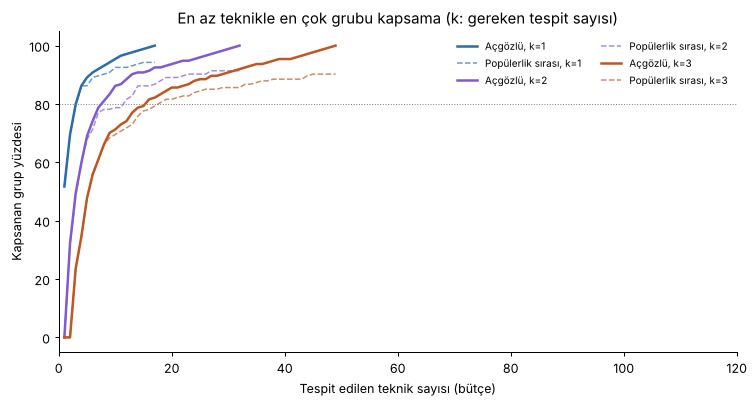

In [13]:
T2G = {t: set(B[t]) for t in T_nodes}

def greedy_cover(k, cand=None):
    cand = set(T_nodes if cand is None else cand)
    need = {g: min(k, len(set(B[g]) & cand)) for g in G_nodes}
    cnt = dict.fromkeys(G_nodes, 0); chosen, curve, gains = [], [], []
    left = set(cand)
    while any(cnt[g] < need[g] for g in G_nodes):
        best = max(sorted(left), key=lambda t: (sum(cnt[g] < need[g] for g in T2G[t]), B.degree(t)))
        gain = sum(1 for g in T2G[best] if cnt[g] + 1 == need[g])
        for g in T2G[best]:
            cnt[g] += 1
        left.discard(best); chosen.append(best); gains.append(gain)
        curve.append(sum(cnt[g] >= need[g] for g in G_nodes))
    return chosen, curve, gains

def popularity_curve(k, n_max):
    need = {g: min(k, B.degree(g)) for g in G_nodes}
    cnt = dict.fromkeys(G_nodes, 0); curve = []
    for t in sorted(T_nodes, key=lambda t: (-B.degree(t), t))[:n_max]:
        for g in T2G[t]:
            cnt[g] += 1
        curve.append(sum(cnt[g] >= need[g] for g in G_nodes))
    return curve

def needed(curve, frac):
    tgt = int(np.ceil(frac * len(G_nodes)))
    return next((i + 1 for i, c in enumerate(curve) if c >= tgt), None)

cover = {}
for k in [1, 2, 3]:
    ch, cu, ga = greedy_cover(k)
    pc = popularity_curve(k, len(T_nodes))
    cover[k] = {"chosen": ch, "curve": cu, "gains": ga, "pop_curve": pc}
summary = pd.DataFrame({f"k={k}": {
    "%50 için (greedy)": needed(v["curve"], .5), "%50 için (popülerlik)": needed(v["pop_curve"], .5),
    "%80 için (greedy)": needed(v["curve"], .8), "%80 için (popülerlik)": needed(v["pop_curve"], .8),
    "%90 için (greedy)": needed(v["curve"], .9), "%90 için (popülerlik)": needed(v["pop_curve"], .9),
    "%100 için (greedy)": len(v["chosen"]), "%100 için (popülerlik)": needed(v["pop_curve"], 1.0),
    "10 teknikle kapsanan %": 100 * v["curve"][min(9, len(v["curve"]) - 1)] / len(G_nodes),
    "20 teknikle kapsanan %": 100 * v["curve"][min(19, len(v["curve"]) - 1)] / len(G_nodes),
} for k, v in cover.items()})
display(summary)

pick = pd.DataFrame({"sıra": range(1, 16), "teknik": [label(t) for t in cover[1]["chosen"][:15]],
                     "taktik": [tactic[t].replace(";", ", ") for t in cover[1]["chosen"][:15]],
                     "kullanan grup": [B.degree(t) for t in cover[1]["chosen"][:15]],
                     "yeni kapsanan": cover[1]["gains"][:15],
                     "kümülatif %": [round(100 * c / len(G_nodes), 1) for c in cover[1]["curve"][:15]]})
pick3 = pd.DataFrame({"sıra": range(1, 16), "teknik": [label(t) for t in cover[3]["chosen"][:15]],
                      "kullanan grup": [B.degree(t) for t in cover[3]["chosen"][:15]],
                      "kümülatif % (k=3)": [round(100 * c / len(G_nodes), 1) for c in cover[3]["curve"][:15]]})
print("k=1 öncelik listesi (ilk 15)"); display(pick)
print("k=3 öncelik listesi (ilk 15)"); display(pick3)
pd.DataFrame({f"k{k}_teknik": pd.Series([label(t) for t in v["chosen"]]) for k, v in cover.items()}).to_csv(RES / "greedy_priority_lists.csv", index_label="sira")
R["coverage"] = {"summary": json.loads(summary.to_json()), "pick_k1": pick.values.tolist(), "pick_k3": pick3.values.tolist(),
                 "curves": {k: v["curve"] for k, v in cover.items()},
                 "pop_curves": {k: v["pop_curve"][:len(v["curve"]) + 20] for k, v in cover.items()},
                 "always_uncoverable_k3": int(sum(B.degree(g) < 3 for g in G_nodes))}
R["unique_techniques"] = int(sum(B.degree(t) == 1 for t in T_nodes))

# Savunma açısından uygulanabilir varyant: yalnızca kurum ağında tespit edilebilir teknikler
# (Keşif / Reconnaissance ve Kaynak Geliştirme / Resource Development taktikleri saldırı öncesi, kurban ağının dışında gerçekleşir)
PRE = {"reconnaissance", "resource-development"}
DETECTABLE = [t for t in T_nodes if not set(tactic[t].split(";")) <= PRE]
det = {}
for k in [1, 3]:
    ch, cu, ga = greedy_cover(k, DETECTABLE)
    det[k] = {"chosen": ch, "curve": cu}
pick_det = pd.DataFrame({"sıra": range(1, 11), "teknik": [label(t) for t in det[3]["chosen"][:10]],
                         "taktik": [tactic[t].replace(";", ", ") for t in det[3]["chosen"][:10]],
                         "kullanan grup": [B.degree(t) for t in det[3]["chosen"][:10]],
                         "kümülatif % (k=3)": [round(100 * c / len(G_nodes), 1) for c in det[3]["curve"][:10]]})
det_sum = {f"k={k}": {"%80 için": needed(v["curve"], .8), "%90 için": needed(v["curve"], .9), "tamamı için": len(v["chosen"]),
                      "10 teknikle %": round(100 * v["curve"][min(9, len(v["curve"]) - 1)] / len(G_nodes), 1),
                      "20 teknikle %": round(100 * v["curve"][min(19, len(v["curve"]) - 1)] / len(G_nodes), 1),
                      "kapsanabilen grup": int(v["curve"][-1])} for k, v in det.items()}
print(f"Tespit edilebilir teknik sayısı: {len(DETECTABLE)} / {len(T_nodes)}")
display(pd.DataFrame(det_sum))
print("Uygulanabilir öncelik listesi — k=3, yalnızca tespit edilebilir teknikler (ilk 10)"); display(pick_det)
R["coverage_detectable"] = {"n_detectable": len(DETECTABLE), "summary": det_sum, "pick_k3": pick_det.values.tolist(),
                            "pick_k1": [label(t) for t in det[1]["chosen"][:10]],
                            "curves": {k: v["curve"] for k, v in det.items()}}

fig, ax = plt.subplots(figsize=(8.5, 4.6))
cols = {1: "#2b6cb0", 2: "#805ad5", 3: "#c05621"}
for k, v in cover.items():
    xs = np.arange(1, len(v["curve"]) + 1)
    ax.plot(xs, 100 * np.array(v["curve"]) / len(G_nodes), color=cols[k], lw=2, label=f"Açgözlü, k={k}")
    pc = v["pop_curve"][:len(v["curve"])]
    ax.plot(np.arange(1, len(pc) + 1), 100 * np.array(pc) / len(G_nodes), color=cols[k], lw=1.2, ls="--", alpha=.7,
            label=f"Popülerlik sırası, k={k}")
ax.axhline(80, color="grey", lw=.8, ls=":"); ax.set_xlim(0, 120)
ax.set_xlabel("Tespit edilen teknik sayısı (bütçe)"); ax.set_ylabel("Kapsanan grup yüzdesi")
ax.set_title("En az teknikle en çok grubu kapsama (k: gereken tespit sayısı)")
ax.legend(fontsize=8, frameon=False, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "fig_greedy_coverage.png", bbox_inches="tight"); plt.show()

**Yorum (kapsama analizi = araştırma sorusu 1'in cevabı)**
* **k = 1:** yalnızca **4 teknik** grupların %86'sını, **6 teknik** %90'ını, **17 teknik** tamamını en az bir teknikten yakalıyor. Popülerlik sırasıyla tamamı için 203 teknik gerekiyor.
* **k = 3 (daha gerçekçi: tek tespit kolay atlatılabilir):** %80 için 16, %90 için 29, tamamı için 49 teknik (popülerlik sırasıyla 18 / 45 / 370).
* **Açgözlü seçimin farkı kuyrukta:** ilk birkaç adımda popüler teknikleri seçiyor, ama sonra popülerlik listesinin çok gerilerinde kalan **tamamlayıcı** teknikleri (ör. T1564.005 Hidden File System, yalnız 2 grup) seçerek kapsanmayan grupları hedefliyor.
* **Uygulanabilir varyant:** T1588.002 Tool gibi Kaynak Geliştirme teknikleri kurum ağında doğrudan görülemez. Yalnız tespit edilebilir tekniklerle k = 3 öncelik listesi ayrıca verildi.
* **Önerimiz:** sınırlı bütçeli bir ekip bu listenin ilk 10–20 tekniğiyle başlamalı (PowerShell, Windows komut satırı, Ingress Tool Transfer, zararlı dosya çalıştırma, oltalama eki, geçerli hesap kullanımı …).
* **Uyarı:** "kapsamak" bir grubun *en az bir kez görülebilmesi* demek; tespitin kalitesi ve yanlış alarm oranı bu analizin dışında.

## 8. Görselleştirme için dışa aktarma
Yerleşim: ForceAtlas2 (iki parçalı ağ, sabit tohum). Aynı koordinatlar hem A3 posterde hem etkileşimli ağda kullanılır.

In [14]:
pos = nx.forceatlas2_layout(B, max_iter=600, seed=SEED, scaling_ratio=2.0, gravity=1.0)
P_arr = np.array(list(pos.values())); lo, hi = P_arr.min(0), P_arr.max(0)
pos = {k: ((v - lo) / (hi - lo) * 1000).round(1).tolist() for k, v in pos.items()}
tech_comm = {}
for t in T_nodes:
    c = {}
    for g in B[t]:
        c[gcomm[g]] = c.get(gcomm[g], 0) + 1 / len(comm_list[gcomm[g]])
    tech_comm[t] = max(sorted(c), key=c.get)
g1_rank = {t: i + 1 for i, t in enumerate(cover[1]["chosen"])}
g3d_rank = {t: i + 1 for i, t in enumerate(det[3]["chosen"])}
out_nodes = []
for r in nodes.itertuples(index=False):
    x = r.node_id
    out_nodes.append({"id": x, "name": r.name, "type": r.node_type, "x": pos[x][0], "y": pos[x][1],
                      "deg": int(B.degree(x)), "btw": round(float(cent.loc[x, "betweenness"]), 5),
                      "pr": round(float(cent.loc[x, "pagerank"]), 5),
                      "comm": gcomm[x] if r.node_type == "group" else tech_comm[x],
                      "jc": (int(jclusters[x]) if x in jclusters.index else None) if r.node_type == "group" else None,
                      "greedy": g1_rank.get(x), "greedy3": g3d_rank.get(x), "tactics": r.tactics, "platforms": r.platforms,
                      "aliases": r.aliases, "sub": bool(r.is_subtechnique), "url": r.url, "desc": r.description})
viz = {"meta": {"attack_version": meta["attack_version"], "nodes": n, "edges": m},
       "communities": [{"id": ci["id"], "size": ci["size"], "tr": ci["name_tr"], "en": ci["name_en"]} for ci in comm_info],
       "jclusters": [{"id": ci["id"], "size": ci["size"], "tr": ci["name_tr"], "en": ci["name_en"]} for ci in jc_info],
       "nodes": out_nodes, "edges": [[a, b] for a, b in B.edges()]}
(ROOT / "web" / "graph_data.json").write_text(json.dumps(viz, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
(RES / "summary.json").write_text(json.dumps(R, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print("web/graph_data.json ve results/summary.json yazıldı.")

web/graph_data.json ve results/summary.json yazıldı.
